# NYC Yellow Taxi: Spark and Neural Network Analysis

This notebook studies taxi trip duration using January 2024 trip data. Run the cells from top to bottom. Each step shows the code and its output.

## 1. Install libraries
These packages are used for Spark processing, data handling, and machine learning.

In [1]:
%pip install pyspark==3.5.3 pyarrow==26.0.0 scikit-learn==1.8.0 pandas numpy matplotlib threadpoolctl

Note: you may need to restart the kernel to use updated packages.


## 2. Get the dataset
Download the January 2024 Parquet file if it is not already in the project folder.

In [2]:
from pathlib import Path
from urllib.request import urlopen
import hashlib
ROOT = Path.cwd()
(ROOT/'data').mkdir(exist_ok=True)
source = ROOT/'yellow_tripdata_2024-01.parquet'
if not source.exists():
    with urlopen('https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet') as response:
        source.write_bytes(response.read())

### Check the file
Record its SHA-256 checksum to confirm that the source file matches the one used for the experiment.

In [3]:
actual = hashlib.sha256(source.read_bytes()).hexdigest()
print('SHA256:', actual)
assert actual == 'c4d59da7bbc8abaeeeb1727947ee93d9891a71acb42854bd80db1571b2030510', 'Source differs from the report; document the new version.'

SHA256: c4d59da7bbc8abaeeeb1727947ee93d9891a71acb42854bd80db1571b2030510


## 3. Import and set up
Set thread limits and load the Python tools used later in the notebook.

In [4]:
import os
os.environ.setdefault('SPARK_LOCAL_IP','127.0.0.1')
os.environ['OMP_NUM_THREADS']='2'
os.environ['OPENBLAS_NUM_THREADS']='2'
os.environ['MKL_NUM_THREADS']='2'
from pathlib import Path
import time,json,hashlib,platform,copy,warnings
import numpy as np
import pandas as pd
from pyspark.sql import SparkSession,functions as F
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from threadpoolctl import threadpool_limits
import sklearn,pyspark

### Start Spark
Use local Spark with two worker threads. This keeps the experiment manageable on a personal computer.

In [5]:
ROOT=Path.cwd()
OUT=ROOT/'results'; OUT.mkdir(exist_ok=True)
rawfile=ROOT/'yellow_tripdata_2024-01.parquet'
spark=(SparkSession.builder.master('local[2]').appName('TaxiDurationReferenceExperiment')
 .config('spark.driver.memory','2g').config('spark.sql.shuffle.partitions','8')
 .config('spark.sql.session.timeZone','UTC').config('spark.sql.execution.arrow.pyspark.enabled','true').getOrCreate())
spark.sparkContext.setLogLevel('ERROR')

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/12 02:50:29 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


### Save experiment details
Keep the dataset checksum, library versions, and Spark settings for reproducibility.

In [6]:
meta={'source_url':'https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet',
 'sha256':hashlib.sha256(rawfile.read_bytes()).hexdigest(),'source_bytes':rawfile.stat().st_size,
 'python':platform.python_version(),'spark':pyspark.__version__,'sklearn':sklearn.__version__,
 'spark_master':spark.sparkContext.master,'driver_memory':'2g','local_worker_threads':2,'seed':42}

## 4. Load the taxi data
Read the Parquet file and check its size and columns.

In [7]:
raw=spark.read.parquet(str(rawfile));meta['raw_rows']=raw.count();meta['raw_columns']=len(raw.columns)
raw.printSchema()
print('Rows:', meta['raw_rows'], '| Columns:', meta['raw_columns'])
raw.show(5, truncate=False)

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)

Rows: 2964624 | Columns: 19


+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|Airport_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|2       |2024-01-01 00:57:55 |2024-01-01 01:17:43  |1              |1.72         |1         |N                 |186         |79          |2           |17.7       |1.0  |0.5    |0.0      

## 5. Create useful features
Calculate trip duration and extract time-related information from the pickup date.

In [8]:
d=(raw.withColumn('duration_min',(F.col('tpep_dropoff_datetime').cast('timestamp').cast('long')-F.col('tpep_pickup_datetime').cast('timestamp').cast('long'))/60)
 .withColumn('pickup_day',F.dayofmonth('tpep_pickup_datetime'))
 .withColumn('hour',F.hour('tpep_pickup_datetime'))
 .withColumn('weekday',F.dayofweek('tpep_pickup_datetime')))
d.select('duration_min', 'pickup_day', 'hour', 'weekday').show(5)

+------------------+----------+----+-------+
|      duration_min|pickup_day|hour|weekday|
+------------------+----------+----+-------+
|              19.8|         1|   0|      2|
|               6.6|         1|   0|      2|
|17.916666666666668|         1|   0|      2|
|               8.3|         1|   0|      2|
|               6.1|         1|   0|      2|
+------------------+----------+----+-------+
only showing top 5 rows



## 6. Clean the records
Keep January pickups, trips lasting 1–120 minutes, and valid taxi location IDs. The remaining row count is shown after every rule.

In [9]:
checks=[('january_pickups',(F.col('tpep_pickup_datetime')>=F.lit('2024-01-01'))&(F.col('tpep_pickup_datetime')<F.lit('2024-02-01'))),
 ('duration_1_to_120',F.col('duration_min').between(1,120)),
 ('known_zones',F.col('PULocationID').between(1,263)&F.col('DOLocationID').between(1,263))]
meta['cleaning']=[]
for name,condition in checks:
 d=d.filter(condition); n=d.count();meta['cleaning'].append({'rule':name,'remaining':n});print('CLEAN',name,n,flush=True)

CLEAN january_pickups 2964606


CLEAN duration_1_to_120 2926743


CLEAN known_zones 2898428


### Summarise the cleaned trips
Select the fields needed for analysis and calculate typical trip-duration values.

In [10]:
d=d.select('tpep_pickup_datetime','pickup_day','hour','weekday','PULocationID','DOLocationID','duration_min').cache()
meta['clean_rows']=d.count()
meta['duration_summary']=d.selectExpr('avg(duration_min) as mean','percentile_approx(duration_min,0.5) as median','stddev(duration_min) as sd').first().asDict()
print('Clean records:', meta['clean_rows'])
print('Trip duration in minutes:', meta['duration_summary'])

Clean records: 2898428
Trip duration in minutes: {'mean': 14.886012101502418, 'median': 11.716666666666667, 'sd': 11.524725515203272}


## 7. Split the data by date
Use earlier dates for training, the next dates for validation, and later dates for testing. This helps avoid mixing time periods.

In [11]:
meta['splits']={}
samples=[]
for name,lo,hi,cap in [('train',1,20,60000),('validation',21,25,15000),('test',26,31,20000)]:
 part=d.filter(F.col('pickup_day').between(lo,hi));n=part.count();meta['splits'][name]={'days':[lo,hi],'eligible':n,'sample':cap}
 # Hash-order provides a repeatable selection; no target values enter predictors.
 sm=(part.orderBy(F.xxhash64('tpep_pickup_datetime','PULocationID','DOLocationID','duration_min')).limit(cap).toPandas())
 sm['split']=name;samples.append(sm)
sample=pd.concat(samples,ignore_index=True)
sample.to_parquet(ROOT/'data/model_sample.parquet',index=False)
print('SAMPLES',meta['splits'],flush=True)
print(sample['split'].value_counts())

SAMPLES {'train': {'days': [1, 20], 'eligible': 1839253, 'sample': 60000}, 'validation': {'days': [21, 25], 'eligible': 474706, 'sample': 15000}, 'test': {'days': [26, 31], 'eligible': 584469, 'sample': 20000}}


split
train         60000
test          20000
validation    15000
Name: count, dtype: int64


## 8. Compare storage formats
Save the same cleaned fields as CSV and Parquet, then compare the file sizes.

In [12]:
size=lambda p:sum(f.stat().st_size for f in p.rglob('*') if f.is_file() and not f.name.startswith('.'))
storecols=['pickup_day','hour','weekday','PULocationID','DOLocationID','duration_min']
bench=d.select(*storecols)
paths={f:ROOT/'data'/('benchmark_'+f) for f in ['csv','parquet']}
for fmt,path in paths.items():
 writer=bench.coalesce(4).write.mode('overwrite')
 if fmt=='csv':writer.option('header','true').csv(str(path))
 else:writer.parquet(str(path))
meta['storage_bytes']={fmt:size(p) for fmt,p in paths.items()}
print('Storage sizes (bytes):', meta['storage_bytes'])

Storage sizes (bytes): {'csv': 84721720, 'parquet': 10873956}


## 9. Benchmark a Spark query
Count morning trips and average duration by pickup zone. We run the same query on CSV and Parquet.

In [13]:
d.unpersist();spark.catalog.clearCache()
def query(fmt):
 if fmt=='csv':x=spark.read.schema(bench.schema).option('header','true').csv(str(paths[fmt]))
 else:x=spark.read.parquet(str(paths[fmt]))
 return x.filter(F.col('hour').between(7,9)).groupBy('PULocationID').agg(F.avg('duration_min').alias('avg_duration'),F.count('*').alias('trips')).orderBy('PULocationID').collect()

### Time the queries
Warm up both readers, then repeat each query three times and compare the results.

In [14]:
# Warm both formats before alternating timed runs; these are warm-cache timings.
query('csv');query('parquet')
times={'csv':[],'parquet':[]};answers={}
for repeat in range(3):
 for fmt in (['csv','parquet'] if repeat%2==0 else ['parquet','csv']):
  start=time.perf_counter();answers[fmt]=query(fmt);times[fmt].append(time.perf_counter()-start)
meta['query_times_seconds']=times
meta['query_result_rows']={f:len(a) for f,a in answers.items()}
meta['query_equivalent']=all(a['PULocationID']==b['PULocationID'] and a['trips']==b['trips'] and abs(a['avg_duration']-b['avg_duration'])<1e-8 for a,b in zip(answers['csv'],answers['parquet']))
print('Query times (seconds):', times)
print('Same results:', meta['query_equivalent'])

Query times (seconds): {'csv': [0.5573687920114025, 0.5769319579994772, 0.5600251659925561], 'parquet': [0.14238654199289158, 0.11490920800133608, 0.09200379200046882]}
Same results: True


### Save Spark results
Write the execution plan and metadata to the results folder, then stop Spark.

In [15]:
(OUT/'spark_physical_plan.txt').write_text(bench._jdf.queryExecution().toString())
(OUT/'metadata.json').write_text(json.dumps(meta,indent=2))
spark.stop()
print('SPARK DONE',times,flush=True)

SPARK DONE {'csv': [0.5573687920114025, 0.5769319579994772, 0.5600251659925561], 'parquet': [0.14238654199289158, 0.11490920800133608, 0.09200379200046882]}


## 10. Review data-preparation results
The following tables show record counts, cleaning steps, sample sizes, and storage performance.

In [16]:
from IPython.display import display, Markdown
import json, pandas as pd
from pathlib import Path
metadata = json.loads((Path.cwd() / "results" / "metadata.json").read_text())
display(pd.DataFrame([{"metric":"Raw rows","value":metadata["raw_rows"]},
                      {"metric":"Raw columns","value":metadata["raw_columns"]},
                      {"metric":"Clean rows","value":metadata["clean_rows"]}]))
display(pd.DataFrame(metadata["cleaning"]))
display(pd.DataFrame([{"split":name, **detail} for name,detail in metadata["splits"].items()]))

,metric,value
0,Raw rows,2964624
1,Raw columns,19
2,Clean rows,2898428


,rule,remaining
0,january_pickups,2964606
1,duration_1_to_120,2926743
2,known_zones,2898428


,split,days,eligible,sample
0,train,"[1, 20]",1839253,60000
1,validation,"[21, 25]",474706,15000
2,test,"[26, 31]",584469,20000


### Compare the benchmark
Show file sizes and average query times for CSV and Parquet.

In [17]:
display(pd.DataFrame([{"format":fmt,"bytes":b,"MiB":round(b/1024**2,2),
                       "query_times_s":metadata["query_times_seconds"][fmt],
                       "mean_query_s":round(sum(metadata["query_times_seconds"][fmt])/len(metadata["query_times_seconds"][fmt]),3)}
                      for fmt,b in metadata["storage_bytes"].items()]))
print("CSV/Parquet query answers equivalent:",metadata["query_equivalent"])
print("Clean trip-duration summary (minutes):",metadata["duration_summary"])

,format,bytes,MiB,query_times_s,mean_query_s
0,csv,84721720,80.80,"[0.5573687920114025, 0.5769319579994772, 0.560...",0.565
1,parquet,10873956,10.37,"[0.14238654199289158, 0.11490920800133608, 0.0...",0.116


CSV/Parquet query answers equivalent: True
Clean trip-duration summary (minutes): {'mean': 14.886012101502418, 'median': 11.716666666666667, 'sd': 11.524725515203272}


## 11. Prepare the model data
Turn time of day and day of week into cyclical features. Then separate inputs into training, validation, and testing sets.

In [18]:
for col,period in [('hour',24),('weekday',7)]:
 sample[col+'_sin']=np.sin(2*np.pi*sample[col]/period)
 sample[col+'_cos']=np.cos(2*np.pi*sample[col]/period)
tr=sample[sample.split=='train'];va=sample[sample.split=='validation'];te=sample[sample.split=='test']
ytr=tr.duration_min.to_numpy();yva=va.duration_min.to_numpy();yte=te.duration_min.to_numpy()
cats=['PULocationID','DOLocationID']
print('Training:', len(tr), 'Validation:', len(va), 'Test:', len(te))

Training: 60000 Validation: 15000 Test: 20000


### Encode and scale features
One-hot encode pickup/drop-off zones and scale the time features. Fit transformations only on the training set.

In [19]:
def transform(cyclic):
 nums=['hour_sin','hour_cos','weekday_sin','weekday_cos'] if cyclic else ['hour','weekday']
 pre=ColumnTransformer([('zones',OneHotEncoder(handle_unknown='ignore',sparse_output=True),cats),('time',StandardScaler(),nums)])
 return pre,pre.fit_transform(tr),pre.transform(va),pre.transform(te)

### Define evaluation metrics
MAE and RMSE measure prediction errors in minutes. R² shows how well the model explains variation in trip duration.

In [20]:
def metrics(y,p):return {'mae':float(mean_absolute_error(y,p)),'rmse':float(np.sqrt(mean_squared_error(y,p))),'r2':float(r2_score(y,p))}
results=[];histories={};predictions={}

## 12. Create a simple baseline
Predict the median training duration for every journey. This gives a basic score to improve on.

In [21]:
median=float(np.median(ytr));pva=np.full(len(va),median);pte=np.full(len(te),median)
results.append({'model':'Median baseline','validation':metrics(yva,pva),'test':metrics(yte,pte),'fit_seconds':0,'epochs':0})
predictions['Median baseline']=pte
print('Median baseline:', results[-1])

Median baseline: {'model': 'Median baseline', 'validation': {'mae': 7.906024444444444, 'rmse': 12.417517068566813, 'r2': -0.09545034473293468}, 'test': {'mae': 7.481105833333333, 'rmse': 11.549578956370853, 'r2': -0.08135998290993585}, 'fit_seconds': 0, 'epochs': 0}


### Train a Ridge regression baseline
A linear model gives a stronger comparison for the neural networks.

In [22]:
pre,Xtr,Xva,Xte=transform(True)
start=time.perf_counter();ridge=Ridge(alpha=10,solver='lsqr').fit(Xtr,ytr)
results.append({'model':'Ridge baseline','validation':metrics(yva,ridge.predict(Xva)),'test':metrics(yte,ridge.predict(Xte)),'fit_seconds':time.perf_counter()-start,'epochs':0})
predictions['Ridge baseline']=ridge.predict(Xte)
print('Ridge baseline:', results[-1])

Ridge baseline: {'model': 'Ridge baseline', 'validation': {'mae': 6.312761076325102, 'rmse': 9.246821394306034, 'r2': 0.39255340301105013}, 'test': {'mae': 6.084667078881303, 'rmse': 8.804640895788706, 'r2': 0.3715636684084592}, 'fit_seconds': 0.02212458400754258, 'epochs': 0}


## 13. Train neural networks
Compare three settings: raw time, cyclical time, and a deeper network. Validation error is used for early stopping.

In [23]:
for name,cyclic,layers in [('MLP1 raw time',False,(32,)),('MLP2 cyclic time',True,(32,)),('MLP3 deeper cyclic',True,(64,32))]:
 pre,Xtr,Xva,Xte=transform(cyclic)
 model=MLPRegressor(hidden_layer_sizes=layers,activation='relu',solver='adam',alpha=0.001,batch_size=256,learning_rate_init=0.001,random_state=42,shuffle=True)
 ymean=ytr.mean();ystd=ytr.std();target=(ytr-ymean)/ystd
 best=None;bestmae=float('inf');bestepoch=0;hist=[];start=time.perf_counter()
 with threadpool_limits(limits=2):
  for epoch in range(1,41):
   model.partial_fit(Xtr,target)
   pv=model.predict(Xva)*ystd+ymean;mae=float(mean_absolute_error(yva,pv))
   hist.append({'epoch':epoch,'train_loss_standardized':float(model.loss_),'validation_mae':mae})
   if mae<bestmae-0.001:bestmae=mae;best=copy.deepcopy(model);bestepoch=epoch
   if epoch-bestepoch>=6:break
 pva=best.predict(Xva)*ystd+ymean;pte=best.predict(Xte)*ystd+ymean
 record={'model':name,'layers':list(layers),'input_features':Xtr.shape[1],'validation':metrics(yva,pva),'test':metrics(yte,pte),'fit_seconds':time.perf_counter()-start,'epochs':epoch,'best_epoch':bestepoch}
 results.append(record);histories[name]=hist;predictions[name]=pte
 print('MODEL',record,flush=True)

MODEL {'model': 'MLP1 raw time', 'layers': [32], 'input_features': 460, 'validation': {'mae': 4.001476160413868, 'rmse': 6.370134690273773, 'r2': 0.7117160955315704}, 'test': {'mae': 3.864809775334198, 'rmse': 6.159785497596057, 'r2': 0.6924121563081795}, 'fit_seconds': 1.4940777919837274, 'epochs': 40, 'best_epoch': 38}


MODEL {'model': 'MLP2 cyclic time', 'layers': [32], 'input_features': 462, 'validation': {'mae': 3.981680932503662, 'rmse': 6.452480253141442, 'r2': 0.7042147362207909}, 'test': {'mae': 3.8342362290243153, 'rmse': 6.136269663744521, 'r2': 0.6947561917581203}, 'fit_seconds': 1.5142324170155916, 'epochs': 40, 'best_epoch': 40}


MODEL {'model': 'MLP3 deeper cyclic', 'layers': [64, 32], 'input_features': 462, 'validation': {'mae': 3.91026145558356, 'rmse': 6.238449081901515, 'r2': 0.7235119060550584}, 'test': {'mae': 3.7743826296334455, 'rmse': 5.9989508733799175, 'r2': 0.7082649562997494}, 'fit_seconds': 1.4928717919974588, 'epochs': 21, 'best_epoch': 15}


## 14. Compare performance across trip types
Choose the neural model with the lowest validation MAE, then check errors for different time periods and long journeys.

In [24]:
bestnn=min([r for r in results if r['model'].startswith('MLP')],key=lambda r:r['validation']['mae'])['model']
groups=[]
for label,mask in [('Morning peak',te.hour.between(7,9)),('Evening peak',te.hour.between(16,19)),('Other hours',~(te.hour.between(7,9)|te.hour.between(16,19))),('Duration over 30 min',te.duration_min>30)]:
 groups.append({'group':label,'n':int(mask.sum()),**metrics(yte[mask],predictions[bestnn][mask])})
print('Selected neural model:', bestnn)
print(pd.DataFrame(groups).to_string(index=False))

Selected neural model: MLP3 deeper cyclic
               group     n       mae      rmse        r2
        Morning peak  2252  4.470301  7.720675  0.625086
        Evening peak  5220  3.683485  5.297034  0.774912
         Other hours 12528  3.687160  5.919880  0.698834
Duration over 30 min  1707 10.499970 14.948220 -0.410479


### Save model results
Export scores, learning histories, subgroup results, and test predictions for the report.

In [25]:
(OUT/'models.json').write_text(json.dumps({'models':results,'selected_neural_model':bestnn,'groups':groups,'histories':histories},indent=2))
pd.DataFrame({'actual_minutes':yte,'predicted_minutes':predictions[bestnn],'hour':te.hour.to_numpy()}).to_csv(OUT/'test_predictions.csv',index=False)
print('ALL DONE',bestnn,flush=True)

ALL DONE MLP3 deeper cyclic


## 15. View model scores
Compare validation and test performance across the baselines and neural networks.

In [26]:
from IPython.display import display
import json, pandas as pd
from pathlib import Path
res = json.loads((Path.cwd() / 'results' / 'models.json').read_text())
rows = [{"model": r["model"],
         "validation_MAE_min":round(r["validation"]["mae"],3),
         "test_MAE_min":round(r["test"]["mae"],3),
         "test_RMSE_min":round(r["test"]["rmse"],3),
         "test_R2":round(r["test"]["r2"],3),
         "epochs":r["epochs"]} for r in res["models"]]
display(pd.DataFrame(rows))
print('Neural model selected by validation MAE:',res['selected_neural_model'])

,model,validation_MAE_min,test_MAE_min,test_RMSE_min,test_R2,epochs
0,Median baseline,7.906,7.481,11.550,-0.081,0
1,Ridge baseline,6.313,6.085,8.805,0.372,0
2,MLP1 raw time,4.001,3.865,6.160,0.692,40
3,MLP2 cyclic time,3.982,3.834,6.136,0.695,40
4,MLP3 deeper cyclic,3.910,3.774,5.999,0.708,21


Neural model selected by validation MAE: MLP3 deeper cyclic


### Inspect predictions
Review errors for different journey groups and look at example test predictions.

In [27]:
display(pd.DataFrame(res['groups']))
display(pd.read_csv(Path.cwd() / 'results' / 'test_predictions.csv').head(10))

,group,n,mae,rmse,r2
0,Morning peak,2252,4.470301,7.720675,0.625086
1,Evening peak,5220,3.683485,5.297034,0.774912
2,Other hours,12528,3.687160,5.919880,0.698834
3,Duration over 30 min,1707,10.499970,14.948220,-0.410479


,actual_minutes,predicted_minutes,hour
0,10.666667,9.749690,13
1,12.233333,7.141901,19
2,6.783333,3.819415,8
3,66.500000,36.782574,13
4,9.166667,11.314078,18
5,7.566667,19.495176,8
6,12.033333,12.802984,0
7,14.816667,12.513712,19
8,13.500000,13.123115,20
9,13.633333,22.175369,19


## 16. Plot learning progress
This chart shows how each neural network’s validation MAE changes during training.

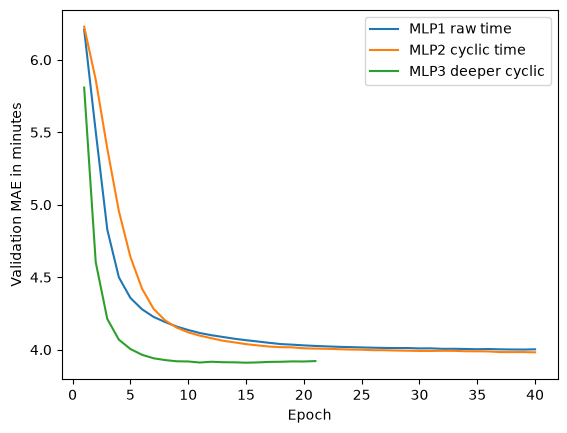

In [28]:
import matplotlib.pyplot as plt
import json
record = json.loads((ROOT/'results/models.json').read_text())
for label, history in record['histories'].items():
    plt.plot([r['epoch'] for r in history], [r['validation_mae'] for r in history], label=label)
plt.xlabel('Epoch'); plt.ylabel('Validation MAE in minutes'); plt.legend(); plt.show()

## 17. What the results mean
Compare the neural networks with the baselines and discuss whether the extra complexity improves the error. Use the tables above rather than assuming one model is always better.

**Limitations:** Spark runs locally rather than across a cluster; only one month is studied; limited pickup-time/location features cannot capture traffic, weather, or unusual events. Benchmarks can also vary by computer and file caching.